In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv('/content/Iris (1).csv')


In [ ]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [ ]:

df_enc

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,8,14,4,1,0
1,1,6,9,4,1,0
2,2,4,11,3,1,0
3,3,3,10,5,1,0
4,4,7,15,4,1,0
...,...,...,...,...,...,...
145,145,24,9,28,19,2
146,146,20,4,26,15,2
147,147,22,9,28,16,2
148,148,19,13,30,19,2


In [ ]:
x = df_enc[['Id','SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']]
y = df_enc['Species']

In [ ]:
x

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0,8,14,4,1
1,1,6,9,4,1
2,2,4,11,3,1
3,3,3,10,5,1
4,4,7,15,4,1
...,...,...,...,...,...
145,145,24,9,28,19
146,146,20,4,26,15
147,147,22,9,28,16
148,148,19,13,30,19


In [ ]:
y

,Species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [ ]:
model = CategoricalNB()
model.fit(x, y)


CategoricalNB()

In [ ]:
test = [0,8,14,4,1]

In [ ]:
test

[0, 8, 14, 4, 1]

In [ ]:
test_samples = [[0, 8, 14, 4, 1]]
print("\n---prediction-----------------------------------")
for t in test_samples:
    row_df = pd.DataFrame([[t[0], t[1], t[2], t[3], t[4]]], columns=x.columns)

    pred = le['Species'].inverse_transform(model.predict(row_df))[0]
    prob = model.predict_proba(row_df)[0]

    orig_day = le['Id'].inverse_transform([t[0]])[0]
    orig_outlook = le['SepalLengthCm'].inverse_transform([t[1]])[0]
    orig_temp = le['SepalWidthCm'].inverse_transform([t[2]])[0]
    orig_humidity = le['PetalLengthCm'].inverse_transform([t[3]])[0]
    orig_wind = le['PetalWidthCm'].inverse_transform([t[4]])[0]

    print(f"input : Id = {orig_day}, SepalLengthCm = {orig_outlook}, SepalWidthCm = {orig_temp}, PetalLengthCm = {orig_humidity}, PetalWidthCm = {orig_wind}")
    print(f"output : Species = {pred}")
    for i, class_name in enumerate(le['Species'].classes_):
        print(f"p({class_name}) = {prob[i]:.4f}")


---prediction-----------------------------------
input : Id = 1, SepalLengthCm = 5.1, SepalWidthCm = 3.5, PetalLengthCm = 1.4, PetalWidthCm = 0.2
output : Species = Iris-setosa
p(Iris-setosa) = 0.9999
p(Iris-versicolor) = 0.0000
p(Iris-virginica) = 0.0000


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 97.33%


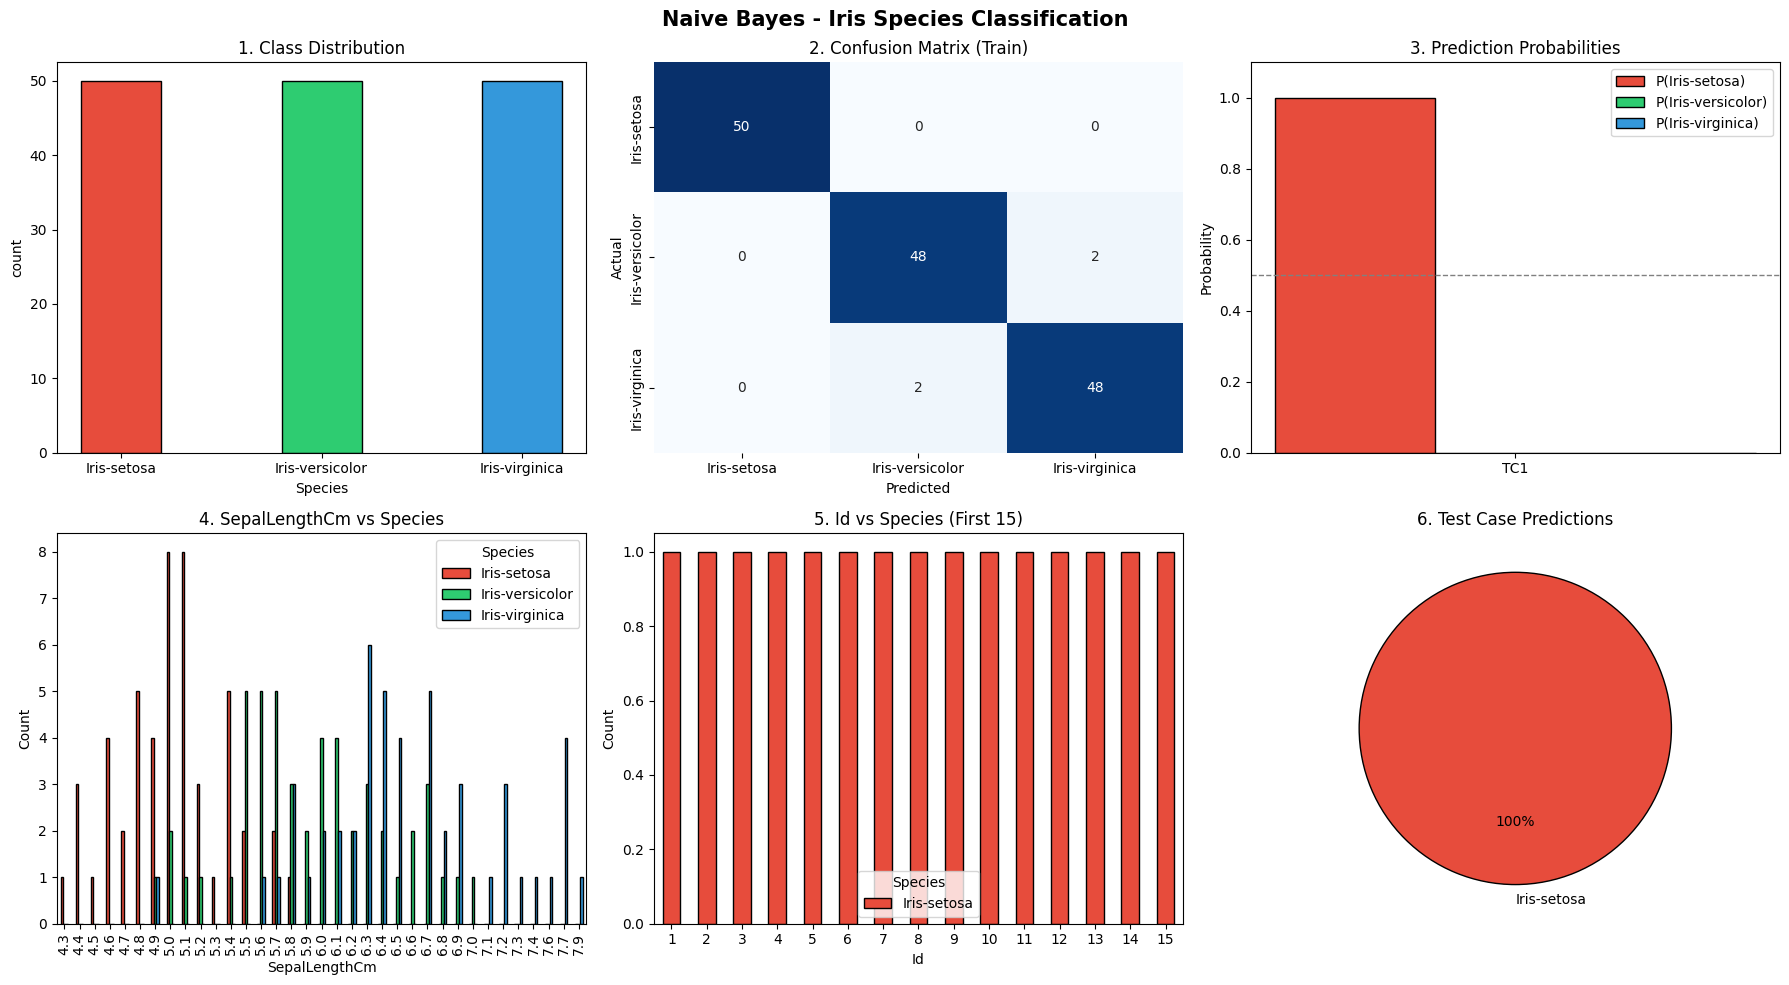

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate predictions for test cases correctly
test_df = pd.DataFrame([test], columns=x.columns)
test_predictions = model.predict(test_df)

# Updated subplot grid to 2 rows and 3 columns to host all 6 plots correctly
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Naive Bayes - Iris Species Classification", fontsize=15, fontweight='bold')

# Get class names and unique colors for 3 classes
classes = le['Species'].classes_
colors = ['#e74c3c', '#2ecc71', '#3498db']

# 1. Class Distribution
counts = df['Species'].value_counts()
axes[0, 0].bar(counts.index.astype(str), counts.values, color=colors, edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Species")
axes[0, 0].set_ylabel("count")

# 2. Confusion Matrix of Training Data
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1], cbar=False,
            xticklabels=classes, yticklabels=classes)
axes[0, 1].set_title("2. Confusion Matrix (Train)")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities (Grouped Bar for 3 classes)
test_cases = [test]
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_indices = np.arange(len(tc_labels))
w = 0.2

for i, class_name in enumerate(classes):
    axes[0, 2].bar(x_indices + (i - 1) * w, [prob[i]], w, label=f'P({class_name})',
                  color=colors[i], edgecolor='black')

axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. SepalLengthCm vs Species
outlook_counts = df.groupby(['SepalLengthCm', 'Species']).size().unstack(fill_value=0)
outlook_counts.plot(
    kind='bar',
    ax=axes[1, 0],
    color=colors,
    edgecolor='black',
    rot=90
)
axes[1, 0].set_title("4. SepalLengthCm vs Species")
axes[1, 0].set_xlabel("SepalLengthCm")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Species")

# 5. Id vs Species (Grouping first 15 for visualization clarity)
temp_counts = df.head(15).groupby(['Id', 'Species']).size().unstack(fill_value=0)
temp_counts.plot(
    kind='bar',
    ax=axes[1, 1],
    color=colors,
    edgecolor='black',
    rot=0
)
axes[1, 1].set_title("5. Id vs Species (First 15)")
axes[1, 1].set_xlabel("Id")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Species")

# 6. Pie Chart - Final Predictions
decoded_predictions = le['Species'].inverse_transform(test_predictions)
pred_counts = pd.Series(decoded_predictions).value_counts()
colors_pie = [colors[list(classes).index(idx)] for idx in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.0f%%',
              colors=colors_pie, startangle=90,
              wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title('6. Test Case Predictions')

plt.tight_layout()
plt.show()